# Beyond STLSQ — the SINDy family

STLSQ is one solver for one formulation. This notebook implements four members of the family that each answer a
limitation met earlier in the module, and measures what each buys on the course benchmarks:

1. **SR3** (sparse relaxed regularized regression): a relaxation that decouples the fit from the sparsity penalty,
   so any regularizer or constraint can be used. Does it select better supports than STLSQ on the noisy vessel?
2. **Constrained SINDy**: impose a physical identity as a linear equality on $\boldsymbol\Xi$. Here the
   energy-conservation identity of the Coriolis terms, $\kappa=0$, which the noisy fits of
   `ed_failure_modes.ipynb` violated.
3. **Bayesian SINDy**: a posterior over the coefficients of the selected model, compared with the bootstrap of
   ensemble-SINDy, and the noise model it silently assumes.
4. **SINDy-PI** (implicit SINDy): rational right-hand sides that no polynomial library can hold sparsely, written as
   an implicit equation $\boldsymbol\Theta(\boldsymbol x,\dot{\boldsymbol x})\boldsymbol\xi=0$.

Parametric SINDy, the fifth member, appears in `ed_sindy_turbine.ipynb`, where the wind speed enters the library as a
parameter.

The prose narrates the **default** run. Change the values below and *Run All*; checks that quote the default numbers are skipped when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
NOISE_LEVELS = [2, 5, 10]        # % of channel std on nu, finite-difference derivatives (SR3 / constrained)
SEEDS = 5                        # noise seeds for the SR3 comparison
THRESHOLDS = [1, 2, 3, 5, 7, 10, 14, 20]   # effective hard thresholds on normalized coefficients
SR3_NU = 10.0                    # SR3 relaxation parameter nu
LAM_WEAK = 1.0                   # weak-form threshold (the vessel notebook's value)
BAYES_NOISE = 0.03               # noise of the ensemble-SINDy example (fraction of channel std)
# --------------------------------------------------------------------------
DEFAULTS = dict(NOISE_LEVELS=[2, 5, 10], SEEDS=5, THRESHOLDS=[1, 2, 3, 5, 7, 10, 14, 20], SR3_NU=10.0, LAM_WEAK=1.0,
                BAYES_NOISE=0.03)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

### Setup: the vessel of `ed_sindy_vessel.ipynb`

Same benchmark, maneuver, library, STLSQ and RK4 as the vessel and failure-mode notebooks, plus the weak-form system
of the vessel notebook and a scorer: the maximum relative error over the twelve true coefficients and the number of
wrong terms (spurious kept plus true deleted, out of $39$).

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted; set_plot_style()
from pyutils.benchmarks import vessel
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

p = vessel.VesselParams()
def tau_fn(t, z): return np.array([150 + 100*np.sin(0.3*t), 90*np.sin(0.5*t + 1), 60*np.sin(0.7*t)])
dt = 0.02; t, Z = vessel.simulate(tau_fn, t_end=80.0, dt=dt, p=p)
nu = Z[:, 3:]; tau = np.array([tau_fn(tk, zk) for tk, zk in zip(t, Z)])
nudot = np.array([vessel.state_derivative(z, tau_fn(tk, z), p)[3:] for tk, z in zip(t, Z)])

def library(nu, tau):
    u, v, r = nu[:, 0], nu[:, 1], nu[:, 2]
    cols = {'1': np.ones_like(u), 'u': u, 'v': v, 'r': r, '|u|u': np.abs(u)*u,
            '|v|v': np.abs(v)*v, '|r|r': np.abs(r)*r, 'uv': u*v, 'ur': u*r, 'vr': v*r,
            'tau1': tau[:, 0], 'tau2': tau[:, 1], 'tau3': tau[:, 2]}
    names = list(cols); return np.stack([cols[n] for n in names], 1), names

def stlsq(Theta, dXdt, lam, n_iter=20):
    norm = np.linalg.norm(Theta, axis=0) + 1e-12; Tn = Theta/norm
    Xi = np.linalg.lstsq(Tn, dXdt, rcond=None)[0]
    for _ in range(n_iter):
        small = np.abs(Xi) < lam; Xi[small] = 0
        for j in range(dXdt.shape[1]):
            big = ~small[:, j]
            if big.any(): Xi[big, j] = np.linalg.lstsq(Tn[:, big], dXdt[:, j], rcond=None)[0]
    return Xi/norm[:, None]

def rk4(deriv, z0, tfn, t_end=40.0, dt=0.02):
    n = int(round(t_end/dt)); tt = np.linspace(0, n*dt, n + 1); Zo = np.empty((n + 1, 6)); z = z0.copy(); Zo[0] = z
    for k in range(n):
        ta = tfn(tt[k], z)
        k1 = deriv(z, ta); k2 = deriv(z + 0.5*dt*k1, ta); k3 = deriv(z + 0.5*dt*k2, ta); k4 = deriv(z + dt*k3, ta)
        z = z + dt/6*(k1 + 2*k2 + 2*k3 + k4); Zo[k + 1] = z
    return tt, Zo

def rollout(Xi_, keep, tfn, t_end):
    # integrate the discovered model (library columns `keep`) from rest
    def deriv(z, ta):
        nuk = z[3:]; Th1, _ = library(nuk[None, :], np.asarray(ta)[None, :])
        return np.concatenate([vessel.rotation(z[2]) @ nuk, (Th1[:, keep] @ Xi_)[0]])
    return rk4(deriv, np.zeros(6), tfn, t_end=t_end)[1]

Theta, names = library(nu, tau); ALL = np.ones(len(names), bool)
Xi = stlsq(Theta, nudot, 0.02)
truth = {'udot': {'vr': 80/55, 'u': -10/55, '|u|u': -5/55, 'tau1': 1/55},
         'vdot': {'ur': -55/80, 'v': -40/80, '|v|v': -40/80, 'tau2': 1/80},
         'rdot': {'uv': -25/30, 'r': -15/30, '|r|r': -10/30, 'tau3': 1/30}}
Xi_true = np.zeros_like(Xi)
for c, eq in enumerate(truth):
    for tm, val in truth[eq].items(): Xi_true[names.index(tm), c] = val
print('full library: max coefficient error vs truth', f'{np.abs(Xi - Xi_true).max():.1e}',
      '| u range in the data', f'[{nu[:, 0].min():.2f}, {nu[:, 0].max():.2f}] m/s',
      '| tau1 range', f'[{tau[:, 0].min():.0f}, {tau[:, 0].max():.0f}] N')

trapz = getattr(np, 'trapezoid', None) or np.trapz      # numpy 2.x / 1.x
def weak_system(nu, tau, t, n_windows=60, width=400, q=4):
    Th, _ = library(nu, tau); m = len(t)
    starts = np.linspace(0, m - width, n_windows).astype(int)
    G = np.empty((n_windows, Th.shape[1])); b = np.empty((n_windows, nu.shape[1]))
    for k, s in enumerate(starts):
        sl = slice(s, s + width); tk = t[sl]; a, bb = tk[0], tk[-1]
        phi = ((tk - a)*(bb - tk))**q; dphi = q*((tk - a)*(bb - tk))**(q - 1)*((bb - tk) - (tk - a))
        scale = trapz(phi, tk); phi, dphi = phi/scale, dphi/scale
        b[k] = -trapz(dphi[:, None]*nu[sl], tk, axis=0); G[k] = trapz(phi[:, None]*Th[sl], tk, axis=0)
    return G, b

active = Xi_true != 0
def score(Xh):
    rel = np.abs(Xh[active] - Xi_true[active])/np.abs(Xi_true[active])
    return float(rel.max()), int(((np.abs(Xh) > 1e-9) != active).sum())
def noisy(lev, seed):
    rng = np.random.default_rng(seed); nu_s = nu + lev/100*nu.std(0)*rng.standard_normal(nu.shape)
    Th_s, _ = library(nu_s, tau); return nu_s, Th_s, np.gradient(nu_s, dt, axis=0)

full library: max coefficient error vs truth 2.1e-15 | u range in the data [-0.78, 3.92] m/s | tau1 range [50, 250] N


## 1. SR3: relax, then threshold

SR3 (Zheng et al., 2019) introduces an auxiliary copy $\mathbf W$ of the coefficients and solves
$$\min_{\boldsymbol\Xi,\mathbf W}\ \tfrac12\|\dot{\mathbf X}-\boldsymbol\Theta\boldsymbol\Xi\|^2+\lambda R(\mathbf W)
+\tfrac{1}{2\nu}\|\boldsymbol\Xi-\mathbf W\|^2 .$$
For fixed $\mathbf W$ the problem in $\boldsymbol\Xi$ is a ridge-like least squares with the closed form
$\boldsymbol\Xi=(\boldsymbol\Theta^\top\boldsymbol\Theta+\mathbf I/\nu)^{-1}(\boldsymbol\Theta^\top\dot{\mathbf X}+\mathbf W/\nu)$;
for fixed $\boldsymbol\Xi$ the problem in $\mathbf W$ is the proximal operator of $\nu\lambda R$, which for
$R=\|\cdot\|_0$ is hard thresholding at $\sqrt{2\lambda\nu}$. Alternate the two, then refit least squares on the
support of $\mathbf W$. The matrix inverse is computed once. To compare like with like, both solvers are run at the
same **effective** threshold $\sqrt{2\lambda\nu}$ on the normalized coefficients.

In [3]:
def sr3(Th, Y, lam, nu_=SR3_NU, n_iter=200):
    norm = np.linalg.norm(Th, axis=0) + 1e-12; Tn = Th/norm
    Hi = np.linalg.inv(Tn.T @ Tn + np.eye(Th.shape[1])/nu_); TY = Tn.T @ Y
    W = np.linalg.lstsq(Tn, Y, rcond=None)[0]; thr = np.sqrt(2*lam*nu_)
    for _ in range(n_iter):
        Xr = Hi @ (TY + W/nu_); W = np.where(np.abs(Xr) > thr, Xr, 0.0)       # relaxed fit, then the l0 prox
    X = np.zeros_like(W)
    for j in range(Y.shape[1]):
        s = W[:, j] != 0
        if s.any(): X[s, j] = np.linalg.lstsq(Tn[:, s], Y[:, j], rcond=None)[0]
    return X/norm[:, None]

wrong = {lev: {'STLSQ': np.zeros((SEEDS, len(THRESHOLDS))), 'SR3': np.zeros((SEEDS, len(THRESHOLDS)))} for lev in NOISE_LEVELS}
for lev in NOISE_LEVELS:
    for s in range(SEEDS):
        _, Th_s, nd = noisy(lev, s)
        for i, th in enumerate(THRESHOLDS):
            wrong[lev]['STLSQ'][s, i] = score(stlsq(Th_s, nd, th))[1]
            wrong[lev]['SR3'][s, i] = score(sr3(Th_s, nd, th**2/(2*SR3_NU)))[1]
print('wrong terms (of 39), median over seeds, at effective threshold', THRESHOLDS)
for lev in NOISE_LEVELS:
    for m in ['STLSQ', 'SR3']:
        print(f'{lev:3d}% {m:6s}', np.median(wrong[lev][m], 0).astype(int))
best = {lev: {m: int(np.median(wrong[lev][m], 0).min()) for m in wrong[lev]} for lev in NOISE_LEVELS}
print('best over thresholds:', best)
if AT_DEFAULTS:
    assert all(abs(best[l]['SR3'] - best[l]['STLSQ']) <= 2 for l in NOISE_LEVELS)

wrong terms (of 39), median over seeds, at effective threshold [1, 2, 3, 5, 7, 10, 14, 20]
  2% STLSQ  [7 0 0 0 0 0 0 1]
  2% SR3    [8 4 0 0 0 0 0 1]
  5% STLSQ  [20  9  7  7  4  0  0  1]
  5% SR3    [21 14 10  8  4  3  0  1]
 10% STLSQ  [25 21 18 12  8  7  5  4]
 10% SR3    [26 21 18 15 11  8  6  6]
best over thresholds: {2: {'STLSQ': 0, 'SR3': 0}, 5: {'STLSQ': 0, 'SR3': 0}, 10: {'STLSQ': 4, 'SR3': 6}}


At matched thresholds SR3 is no better a selector than STLSQ on this data: both reach the exact support at $2\%$ and
$5\%$ noise (at thresholds of $2$ and $10$ respectively), STLSQ gets there at slightly smaller thresholds, and at
$10\%$ its best is $4$ wrong terms against SR3's $6$. Both need a threshold far above the vessel notebook's $\lambda=1$ once the noise reaches $5\%$. SR3's value
is the *framework*: the relaxation separates the least-squares geometry from the penalty, so the penalty can be
$\ell_0$, $\ell_1$, a group penalty, or the indicator of a constraint set, and the alternation has convergence
guarantees that STLSQ's ad hoc loop does not. That is how PySINDy implements constrained and trapping SINDy.

## 2. Constrained SINDy: enforce $\kappa=0$

`ed_failure_modes.ipynb` showed that noisy fits break the energy identity of the Coriolis terms,
$\kappa=m_{11}\xi_{u,vr}+m_{22}\xi_{v,ur}+m_{33}\xi_{r,uv}=0$. With the mass matrix known (a hull model gives it), the
identity is one linear equation $\mathbf c^\top\mathrm{vec}(\boldsymbol\Xi)=0$ coupling the three equations. Each
STLSQ refit becomes an equality-constrained least-squares problem, solved with its KKT system
$$\begin{bmatrix}\mathbf A&\mathbf c\\\mathbf c^\top&0\end{bmatrix}\begin{bmatrix}\boldsymbol\xi\\\mu\end{bmatrix}
=\begin{bmatrix}\boldsymbol\Theta^\top\dot{\boldsymbol x}\\0\end{bmatrix},$$
with $\mathbf A$ block-diagonal over the equations (restricted to the active terms) and $\mu$ the Lagrange multiplier.

In [4]:
m11, m22, m33 = np.diag(p.M()); NP = len(names)
cvec = np.zeros((NP, 3)); cvec[names.index('vr'), 0] = m11; cvec[names.index('ur'), 1] = m22; cvec[names.index('uv'), 2] = m33
def kappa(X): return float((cvec*X).sum())

def stlsq_c(Th, Y, lam, constrain=True, n_iter=20):
    # STLSQ on all three equations at once; each refit is the KKT solve of least squares subject to kappa = 0
    norm = np.linalg.norm(Th, axis=0) + 1e-12; Tn = Th/norm; Cn = cvec/norm[:, None]
    act = np.ones((NP, 3), bool)
    for it in range(n_iter + 1):
        idx = [(i, j) for j in range(3) for i in range(NP) if act[i, j]]
        A = np.zeros((len(idx), len(idx))); b = np.zeros(len(idx)); c = np.array([Cn[i, j] for i, j in idx])
        for j in range(3):
            ii = [n for n, (_, jj) in enumerate(idx) if jj == j]; G = Tn[:, [idx[n][0] for n in ii]]
            A[np.ix_(ii, ii)] = G.T @ G; b[ii] = G.T @ Y[:, j]
        if constrain and np.any(c != 0):
            sol = np.linalg.solve(np.block([[A, c[:, None]], [c[None, :], np.zeros((1, 1))]]), np.r_[b, 0.0])[:-1]
        else:
            sol = np.linalg.solve(A, b)
        X = np.zeros((NP, 3))
        for n, (i, j) in enumerate(idx): X[i, j] = sol[n]
        new = act & (np.abs(X) >= lam)
        if it > 0 and (new == act).all(): break
        act = new
    return X/norm[:, None]

TC = vessel.turning_circle(400.0, 60.0); _, Z_tc = vessel.simulate(TC, t_end=200.0, dt=0.02, p=p)
def path200(X): return float(np.linalg.norm(rollout(X, ALL, TC, 200.0)[-1, :3] - Z_tc[-1, :3]))
rows_c = []
for lev in NOISE_LEVELS:
    nu_s, Th_s, nd = noisy(lev, 0); G, bw = weak_system(nu_s, tau, t)
    for lab, (A_, B_, lam) in [('finite diff.', (Th_s, nd, 0.1)), ('weak form', (G, bw, LAM_WEAK))]:
        X0, X1 = stlsq_c(A_, B_, lam, False), stlsq_c(A_, B_, lam, True)
        rows_c.append((lev, lab, kappa(X0), score(X0), path200(X0), kappa(X1), score(X1), path200(X1)))
print(f'{"noise":>5} {"method":>12} | {"kappa":>7} {"max err":>8} {"wrong":>5} {"path":>7} || {"kappa":>8} {"max err":>8} {"wrong":>5} {"path":>7}')
print(' ' * 20 + 'unconstrained' + ' ' * 22 + 'constrained (kappa = 0)')
for lev, lab, k0, s0, p0, k1, s1, p1 in rows_c:
    print(f'{lev:4d}% {lab:>12} | {k0:+7.2f} {s0[0]:8.3f} {s0[1]:5d} {p0:6.2f}m || {k1:+8.1e} {s1[0]:8.3f} {s1[1]:5d} {p1:6.2f}m')
if AT_DEFAULTS:
    assert all(abs(r[5]) < 1e-9 for r in rows_c)

noise       method |   kappa  max err wrong    path ||    kappa  max err wrong    path
                    unconstrained                      constrained (kappa = 0)
   2% finite diff. |   +2.24    0.083    25   2.18m || -1.4e-14    0.075    22   2.16m
   2%    weak form |   +0.25    0.021     0   0.16m || +0.0e+00    0.020     0   0.17m
   5% finite diff. |  +10.50    0.344    26  10.71m || -2.1e-14    0.339    26  10.43m
   5%    weak form |   +0.71    0.052     0   0.41m || +3.6e-15    0.047     0   0.43m
  10% finite diff. |  +21.20    0.665    27  40.68m || -7.1e-15    0.761    26  39.92m
  10%    weak form |   +1.70    0.099     0   0.80m || -7.1e-15    0.086     0   0.85m


The constraint does exactly what it promises: $\kappa=0$ to rounding, for every fit. What it does *not* do on this
benchmark is make the models much more accurate. The weak-form coefficient errors drop by about a tenth
($5.2\to4.7\%$ at $5\%$ noise, $9.9\to8.6\%$ at $10\%$), the rollouts barely move, and the dense finite-difference
models stay dense (at $10\%$ the constraint even worsens their largest coefficient error, $0.67\to0.76$: forcing an
identity onto a wrong support moves the error elsewhere). The vessel's strong drag already keeps every model bounded, so a model that injects a little
energy through its Coriolis terms is still stable. The constraint buys **physical consistency**, a guarantee that
holds outside the data, not a better fit inside it. On systems where that guarantee decides boundedness (lightly
damped fluids, energy-conserving quadratic models), trapping SINDy goes further and constrains the quadratic terms
so that every trajectory provably enters a bounded region.

## 3. Bayesian SINDy: a posterior over the coefficients

Fix the support selected by STLSQ and put a flat prior on its coefficients. If the residuals are independent
Gaussians, the posterior is Gaussian, with mean equal to the least-squares solution and covariance
$$\mathrm{Cov}(\boldsymbol\xi\mid\text{data})=\hat\sigma^2(\boldsymbol\Theta_S^\top\boldsymbol\Theta_S)^{-1},\qquad
\hat\sigma^2=\frac{\|\dot{\boldsymbol x}-\boldsymbol\Theta_S\hat{\boldsymbol\xi}\|^2}{m-k}.$$
The posterior standard deviations are the Bayesian counterpart of the bootstrap spread of ensemble-SINDy. Full
Bayesian SINDy also puts a sparsity prior on the *support* (spike-and-slab, or the regularized horseshoe) and samples
it, so the term inclusion probabilities come out of the posterior too; the conjugate case below shows the mechanics
and the assumption both versions share.

In [5]:
np.random.seed(0)                                         # the noise of the vessel notebook's ensemble example
nu_b = nu + BAYES_NOISE*nu.std(0)*np.random.randn(*nu.shape); nd_b = nudot + BAYES_NOISE*nudot.std(0)*np.random.randn(*nudot.shape)
Th_b, _ = library(nu_b, tau)
def posterior(A, y):
    xi = np.linalg.lstsq(A, y, rcond=None)[0]; r = y - A @ xi; s2 = r @ r/(len(y) - A.shape[1])
    return xi, np.sqrt(np.diag(s2*np.linalg.inv(A.T @ A))), r
S_b = np.abs(stlsq(Th_b, nd_b, 0.04)[:, 0]) > 1e-9
xi_b, sd_b, r_b = posterior(Th_b[:, S_b], nd_b[:, 0])
rng = np.random.default_rng(0)
boot = np.array([np.linalg.lstsq(Th_b[i][:, S_b], nd_b[i, 0], rcond=None)[0]
                 for i in (rng.integers(0, len(t), len(t)) for _ in range(80))])
print(f'(a) independent noise on (nu, nu_dot), {BAYES_NOISE*100:g} %: residual lag-1 autocorrelation {np.corrcoef(r_b[:-1], r_b[1:])[0, 1]:+.3f}')
print(f'{"term":>6} {"mean":>8} {"posterior sd":>13} {"bootstrap sd":>13} {"truth":>8}')
for n_, m_, s_, bs in zip(np.array(names)[S_b], xi_b, sd_b, boot.std(0)):
    if abs(Xi_true[names.index(n_), 0]) > 0: print(f'{n_:>6} {m_:+8.4f} {s_:13.4f} {bs:13.4f} {Xi_true[names.index(n_), 0]:+8.4f}')

S_true = active[:, 0]
_, Th_f, nd_f = noisy(2, 0); xi_f, sd_f, r_f = posterior(Th_f[:, S_true], nd_f[:, 0])
draws = np.array([np.linalg.lstsq(noisy(2, 100 + s)[1][:, S_true], noisy(2, 100 + s)[2][:, 0], rcond=None)[0] for s in range(30)])
print(f'\n(b) 2 % noise on nu, finite-difference nu_dot, true support: residual autocorrelation lag 1 '
      f'{np.corrcoef(r_f[:-1], r_f[1:])[0, 1]:+.3f}, lag 2 {np.corrcoef(r_f[:-2], r_f[2:])[0, 1]:+.3f}')
print(f'{"term":>6} {"mean":>8} {"posterior sd":>13} {"sd over 30 noise draws":>23}')
for n_, m_, s_, ds in zip(np.array(names)[S_true], xi_f, sd_f, draws.std(0)):
    print(f'{n_:>6} {m_:+8.4f} {s_:13.4f} {ds:23.4f}')
ratio = float(np.median(sd_f/draws.std(0)))
print(f'posterior sd / actual sd (median): {ratio:.1f}')
if AT_DEFAULTS:
    assert ratio > 3

(a) independent noise on (nu, nu_dot), 3 %: residual lag-1 autocorrelation -0.002
  term     mean  posterior sd  bootstrap sd    truth
     u  -0.1773        0.0049        0.0045  -0.1818
  |u|u  -0.0906        0.0016        0.0015  -0.0909
    vr  +1.4290        0.0027        0.0026  +1.4545
  tau1  +0.0179        0.0000        0.0000  +0.0182

(b) 2 % noise on nu, finite-difference nu_dot, true support: residual autocorrelation lag 1 +0.006, lag 2 -0.477
  term     mean  posterior sd  sd over 30 noise draws
     u  -0.1857        0.0307                  0.0036
  |u|u  -0.0886        0.0100                  0.0010
    vr  +1.4457        0.0179                  0.0035
  tau1  +0.0181        0.0003                  0.0001
posterior sd / actual sd (median): 6.8


With independent noise (a) the posterior and the bootstrap agree to within about $10\%$ on every true term. With
finite-difference derivatives (b) the residuals are not independent: the central difference
$(\nu_{k+1}-\nu_{k-1})/2\Delta t$ shares samples with its neighbours two steps away, which gives a lag-2
autocorrelation of $-0.48$. The posterior, which assumes independence, then misstates the uncertainty: its standard
deviations are several times larger than the actual spread of the estimates over thirty fresh noise draws. A
Bayesian posterior is exactly as good as its likelihood; for differentiated data the likelihood must model the
correlation (or the weak form must be used, whose rows are nearly independent when the windows do not overlap much).

## 4. SINDy-PI: rational dynamics as an implicit equation

Take a right-hand side that is a ratio, the Michaelis--Menten law of enzyme kinetics
$$\dot x=0.6-\frac{1.5\,x}{0.3+x},$$
a standard example for this variant. No polynomial library holds it sparsely: its Taylor series has every power.
Multiply through by the denominator, $(0.3+x)\dot x=0.18-0.9x$, and the equation becomes *linear* in the library
$\boldsymbol\Theta(x,\dot x)=[1,\,x,\,x^2,\,\dot x,\,x\dot x,\,x^2\dot x]$: we want a sparse $\boldsymbol\xi$ with
$\boldsymbol\Theta\boldsymbol\xi=0$. SINDy-PI (Kaheman, Kutz & Brunton, 2020) avoids the trivial solution
$\boldsymbol\xi=0$ by moving each candidate in turn to the left-hand side, $\theta_j=\boldsymbol\Theta_{-j}\boldsymbol\xi$,
solving each by STLSQ, and keeping the sparse fits with zero error. Data: five trajectories from different initial
conditions on $[0,4]$, exact derivatives.

In [6]:
from scipy.integrate import solve_ivp
mm = lambda t_, x_: 0.6 - 1.5*x_/(0.3 + x_)
traj = [solve_ivp(mm, [0, 4], [x0], t_eval=np.linspace(0, 4, 201), rtol=1e-10, atol=1e-12).y[0] for x0 in [0.05, 0.5, 1.0, 2.0, 3.0]]
xm = np.concatenate(traj); xdm = mm(0, xm)
print(f'{len(xm)} samples, x in [{xm.min():.3f}, {xm.max():.3f}]')

def stlsq1(Theta, y, lam, n_iter=20):
    # STLSQ on normalized columns and target (lambda dimensionless), one target
    norm = np.linalg.norm(Theta, axis=0) + 1e-12; Tn = Theta/norm; ny = np.linalg.norm(y); yn = y/ny
    xi = np.linalg.lstsq(Tn, yn, rcond=None)[0]
    for _ in range(n_iter):
        sm = np.abs(xi) < lam; xi[sm] = 0; b = ~sm
        if b.any(): xi[b] = np.linalg.lstsq(Tn[:, b], yn, rcond=None)[0]
    return xi*ny/norm

POLY = np.stack([xm**k for k in range(6)], 1)
xi_poly = stlsq1(POLY, xdm, 0.1)
err_poly = np.linalg.norm(POLY @ xi_poly - xdm)/np.linalg.norm(xdm)
print('explicit SINDy, library {1, x, ..., x^5}:', ' '.join(f'{v:+.3f} x^{k}' for k, v in enumerate(xi_poly) if abs(v) > 1e-12),
      f'  ({int((np.abs(xi_poly) > 1e-12).sum())} terms, rel. fit error {err_poly:.3f})')

PI_NAMES = ['1', 'x', 'x^2', 'xd', 'x xd', 'x^2 xd']
L = np.stack([np.ones_like(xm), xm, xm**2, xdm, xm*xdm, xm**2*xdm], 1)
sv = np.linalg.svd(L/np.linalg.norm(L, axis=0), compute_uv=False)
print('singular values of the normalized implicit library:', np.array2string(sv, precision=1))
pi_models = []
for j in range(6):
    o = [k for k in range(6) if k != j]; xi_ = stlsq1(L[:, o], L[:, j], 0.1)
    e = np.linalg.norm(L[:, o] @ xi_ - L[:, j])/np.linalg.norm(L[:, j])
    pi_models.append((PI_NAMES[j], int((np.abs(xi_) > 1e-12).sum()), e, {PI_NAMES[k]: v for k, v in zip(o, xi_) if abs(v) > 1e-12}))
    print(f'  LHS {PI_NAMES[j]:7s} terms {pi_models[-1][1]}  rel. error {e:.1e}  ', {k: round(v, 4) for k, v in pi_models[-1][3].items()})

1005 samples, x in [0.050, 3.000]
explicit SINDy, library {1, x, ..., x^5}: +0.438 x^0 -2.741 x^1 +3.197 x^2 -1.965 x^3 +0.589 x^4 -0.068 x^5   (6 terms, rel. fit error 0.021)
singular values of the normalized implicit library: [2.2e+00 8.7e-01 4.3e-01 8.9e-02 5.0e-16 2.8e-16]
  LHS 1       terms 3  rel. error 3.0e-15   {'x': np.float64(5.0), 'xd': np.float64(1.6667), 'x xd': np.float64(5.5556)}
  LHS x       terms 3  rel. error 8.8e-16   {'1': np.float64(0.2), 'xd': np.float64(-0.3333), 'x xd': np.float64(-1.1111)}
  LHS x^2     terms 2  rel. error 1.7e-02   {'x xd': np.float64(-0.7473), 'x^2 xd': np.float64(-1.0534)}
  LHS xd      terms 3  rel. error 4.0e-15   {'1': np.float64(0.6), 'x': np.float64(-3.0), 'x xd': np.float64(-3.3333)}
  LHS x xd    terms 5  rel. error 8.9e-16   {'1': np.float64(0.1761), 'x': np.float64(-0.8675), 'x^2': np.float64(-0.0651), 'xd': np.float64(-0.2935), 'x^2 xd': np.float64(-0.0723)}
  LHS x^2 xd  terms 3  rel. error 4.1e-16   {'x': np.float64(0.18), 'x^2

Two singular values are at rounding level: the implicit library has a **two-dimensional** null space, because if
$(0.3+x)\dot x-0.18+0.9x=0$ then so is $x$ times it, which lives in the same library through $x^2$ and $x^2\dot x$.
Several left-hand sides therefore give exact three-term fits; they are the true relation and its multiple by $x$, and
SINDy-PI keeps the one without a common factor. With $\dot x$ on the left the fit is
$\dot x=0.6-3x-3.333\,x\dot x$, i.e. $\dot x=(0.6-3x)/(1+3.333x)=0.6-1.5x/(0.3+x)$, the law exactly. The check
below solves the selected model for $\dot x$ and compares both models outside the data.

max |error| of x_dot on x in [0, 6]:  SINDy-PI 1.4e-15;  polynomial 0.162 inside the data (x <= 3), 87.5 outside


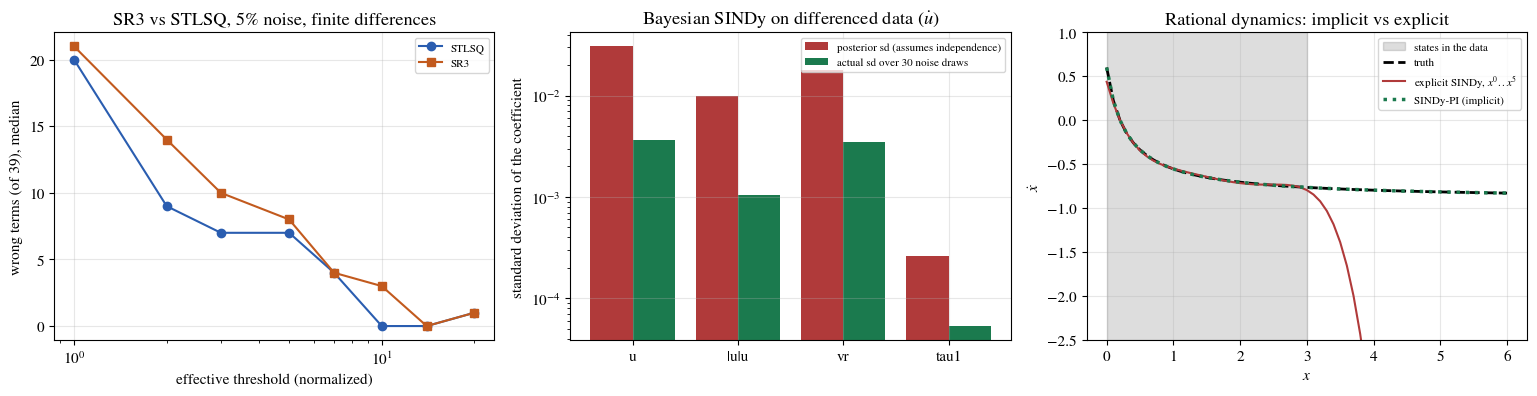

In [7]:
c = pi_models[PI_NAMES.index('xd')][3]
def xd_pi(x_):   # solve  xd = c1 + cx x + cxxd x xd  for xd
    return (c.get('1', 0) + c.get('x', 0)*x_ + c.get('x^2', 0)*x_**2)/(1 - c.get('x xd', 0)*x_ - c.get('x^2 xd', 0)*x_**2)
xg = np.linspace(0.0, 6.0, 61)
e_pi = np.abs(xd_pi(xg) - mm(0, xg)).max()
e_poly_in = np.abs(np.stack([xg**k for k in range(6)], 1) @ xi_poly - mm(0, xg))[xg <= 3].max()
e_poly_out = np.abs(np.stack([xg**k for k in range(6)], 1) @ xi_poly - mm(0, xg))[xg > 3].max()
print(f'max |error| of x_dot on x in [0, 6]:  SINDy-PI {e_pi:.1e};  polynomial {e_poly_in:.3f} inside the data (x <= 3), '
      f'{e_poly_out:.1f} outside')
if AT_DEFAULTS:
    assert e_pi < 1e-6 and e_poly_out > 1.0

def plot_variants():
    fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.1))
    lev = 5
    for m, col, mk in [('STLSQ', 'C0', 'o'), ('SR3', 'C1', 's')]:
        ax[0].plot(THRESHOLDS, np.median(wrong[lev][m], 0), mk + '-', color=col, label=m)
    ax[0].set(xscale='log', xlabel='effective threshold (normalized)', ylabel='wrong terms (of 39), median',
              title=f'SR3 vs STLSQ, {lev}% noise, finite differences'); ax[0].legend(fontsize=8)
    terms = [n_ for n_ in np.array(names)[S_true]]; xs = np.arange(len(terms))
    ax[1].bar(xs - 0.2, sd_f, 0.4, color='C3', label='posterior sd (assumes independence)')
    ax[1].bar(xs + 0.2, draws.std(0), 0.4, color='C2', label='actual sd over 30 noise draws')
    ax[1].set_xticks(xs); ax[1].set_xticklabels(terms); ax[1].set_yscale('log')
    ax[1].set(ylabel='standard deviation of the coefficient', title='Bayesian SINDy on differenced data ($\\dot u$)')
    ax[1].legend(fontsize=8)
    ax[2].axvspan(0, xm.max(), color=muted(), alpha=0.2, label='states in the data')
    ax[2].plot(xg, mm(0, xg), '--', color=fg(), lw=2, label='truth')
    ax[2].plot(xg, np.stack([xg**k for k in range(6)], 1) @ xi_poly, color='C3', label='explicit SINDy, $x^0..x^5$')
    ax[2].plot(xg, xd_pi(xg), ':', color='C2', lw=2.5, label='SINDy-PI (implicit)')
    ax[2].set(xlabel='$x$', ylabel='$\\dot x$', ylim=(-2.5, 1.0), title='Rational dynamics: implicit vs explicit')
    ax[2].legend(fontsize=8); plt.tight_layout()

save_dual(plot_variants, 'ed_variants', FIG)
plt.show()

In [8]:
# the three panels again, one figure each, for the lecture slides
def one(fn, name, size=(6.2, 3.9)):
    def f():
        fig, a = plt.subplots(figsize=size); fn(a); plt.tight_layout()
    save_dual(f, name, FIG); plt.close('all')
def p_sr3(a):
    for m, col, mk in [('STLSQ', 'C0', 'o'), ('SR3', 'C1', 's')]:
        a.plot(THRESHOLDS, np.median(wrong[5][m], 0), mk + '-', color=col, label=m)
    a.set(xscale='log', xlabel='effective threshold (normalized)', ylabel='wrong terms (of 39), median',
          title='5% noise: same supports at matched thresholds'); a.legend(fontsize=8)
def p_bayes(a):
    terms = list(np.array(names)[S_true]); xs = np.arange(len(terms))
    a.bar(xs - 0.2, sd_f, 0.4, color='C3', label='posterior sd (assumes independent noise)')
    a.bar(xs + 0.2, draws.std(0), 0.4, color='C2', label='actual sd over 30 noise draws')
    a.set_xticks(xs); a.set_xticklabels(terms); a.set_yscale('log')
    a.set(ylabel='sd of the coefficient ($\\dot u$)', title='Differenced data: posterior 7x too wide'); a.legend(fontsize=8)
def p_pi(a):
    a.axvspan(0, xm.max(), color=muted(), alpha=0.2, label='states in the data')
    a.plot(xg, mm(0, xg), '--', color=fg(), lw=2, label='truth')
    a.plot(xg, np.stack([xg**k for k in range(6)], 1) @ xi_poly, color='C3', label='polynomial SINDy, $x^0..x^5$')
    a.plot(xg, xd_pi(xg), ':', color='C2', lw=2.5, label='SINDy-PI (implicit)')
    a.set(xlabel='$x$', ylabel='$\\dot x$', ylim=(-2.5, 1.0), title='Rational law: implicit is exact'); a.legend(fontsize=8)
one(p_sr3, 'ed_var_sr3'); one(p_bayes, 'ed_var_bayes'); one(p_pi, 'ed_var_pi')
print('saved ed_var_sr3, ed_var_bayes, ed_var_pi')

saved ed_var_sr3, ed_var_bayes, ed_var_pi


**Takeaways.** The variants answer different questions, and none of them is a free accuracy upgrade.
SR3 selects the same supports as STLSQ at a matched threshold, but turns sparse regression into a framework that can
take any penalty or constraint. Constrained SINDy enforces a physical identity exactly, which buys consistency
outside the data rather than a better fit inside it. Bayesian SINDy turns the fit into a posterior, which is only as
honest as its noise model: for differenced data, independence is wrong. SINDy-PI recovers a rational law exactly
where an explicit polynomial library is dense inside the data and wrong outside it, at the price of a null space with
more than one solution and of $\dot x$ appearing as a regressor, which brings back the errors-in-variables problem of
`ed_failure_modes.ipynb` when the data are noisy (the weak form of SINDy-PI is the remedy used in practice).